# Mixed memberships: the MM-OLBM

In the ordinal latent block model, a voter belongs to one group. In the **mixed-membership
ordinal latent block model** (MM-OLBM, `MixedMembershipBlockModel`), a voter has a degree
of membership to each group and takes **one role per block**: the group it follows on
that block. A voter can agree with one group on one block and with another group on
another block. Each item, likewise, shares its membership between blocks.

This notebook:

1. loads a collective where 30 voters out of 150 are shared between two groups;
2. estimates the single-membership model first;
3. estimates the MM-OLBM, from a spectral start and from the single-membership result;
4. reads the memberships, the roles and the changes of role, and draws them;
5. compares the two models on held-out votes.

The data are **synthetic** (see `data/make_data.py`). Requirements:
`pip install "civiqhub-selene[viz]"`, run from the `examples/` folder.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from loading import read_memberships, read_votes

from civiqhub_selene import viz
from civiqhub_selene.blocks import (
    FixedStart,
    LatentBlockModel,
    MixedMembershipBlockModel,
    RandomStart,
    SpectralStart,
)

plt.rcParams["figure.dpi"] = 90

## 1. Load the votes

In [2]:
votes = read_votes("data/assembly.votes.csv")
voter_ids, planted_memberships = read_memberships("data/assembly.voters.csv")
shared = planted_memberships.max(axis=1) < 1
print(votes)
print(f"{shared.sum()} voters planted with a shared membership")

VoteMatrix(150 voters x 20 items, 1622 votes, 5 levels)
90.7% of the 3000 cells shown, 59.6% of the shown cells voted
30 voters planted with a shared membership


## 2. One group per voter first

SingleCoclustering(150 voters in 3 groups x 20 items in 2 blocks)
groups of 46, 49, 55 voters; blocks of 8, 12 items
group 0 x block 0: vote rate 0.87, typical score +2, 296 votes
group 0 x block 1: vote rate 0.53, typical score -2, 267 votes
group 1 x block 0: vote rate 0.55, typical score -2, 188 votes
group 1 x block 1: vote rate 0.84, typical score +2, 452 votes
group 2 x block 0: vote rate 0.42, typical score 0, 166 votes
group 2 x block 1: vote rate 0.42, typical score 0, 253 votes


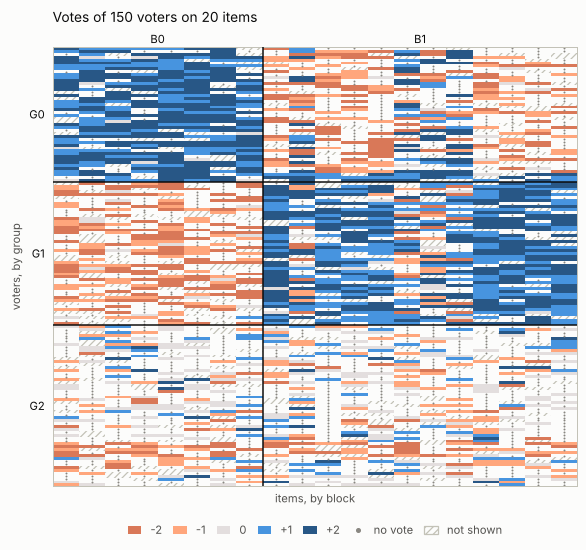

In [3]:
single = (
    LatentBlockModel(n_groups=3, n_blocks=2, initialization=SpectralStart())
    .estimate(votes, seed=0)
    .value
)
print(single)
viz.plot_vote_matrix(votes, single)
plt.show()

## 3. The MM-OLBM

The model is estimated by expectation-maximisation. The expectation step is **exact**:
with $Q$ groups and $L$ blocks, it enumerates the $Q^L$ profiles (one role per block) of
each voter. The memberships are regularised by Dirichlet priors (`voter_concentration`,
`item_concentration`). The objective is the observed log-likelihood plus the log-prior.

Two starts are compared: the spectral arrangement, and the arrangement the
single-membership model found (`FixedStart.from_coclustering`), which the provenance
then cites.

In [4]:
starts = {
    "spectral": (SpectralStart(), 2),
    "from the OLBM": (FixedStart.from_coclustering(single), 1),
}
results = {}
for name, (initialization, n_starts) in starts.items():
    model = MixedMembershipBlockModel(
        n_groups=3,
        n_blocks=2,
        n_starts=n_starts,
        max_iterations=400,
        initialization=initialization,
    )
    results[name] = model.estimate(votes, seed=0)
    mixed = results[name].value
    print(
        f"{name:<14} objective {mixed.objective:9.2f}   log-likelihood "
        f"{mixed.log_likelihood:9.2f}   {mixed.history.n_iterations} iterations"
    )

spectral       objective  -3491.34   log-likelihood  -3338.00   42 iterations
from the OLBM  objective  -3491.34   log-likelihood  -3338.00   42 iterations


Both starts reach the same optimum. Single random starts do not always: out of ten, count
how many reach it.

In [5]:
for name, initialization in (("random", RandomStart()), ("spectral", SpectralStart())):
    model = MixedMembershipBlockModel(
        n_groups=3, n_blocks=2, n_starts=1, max_iterations=400, initialization=initialization
    )
    objectives = [model.estimate(votes, seed=seed).value.objective for seed in range(10)]
    reached = np.mean(
        [objective > results["spectral"].value.objective - 1e-3 for objective in objectives]
    )
    print(f"{name:<9} single starts that reach the optimum: {reached:.0%}")

random    single starts that reach the optimum: 40%


spectral  single starts that reach the optimum: 100%


In [6]:
result = results["spectral"]
mixed = result.value
print(result)

Result(mixed_membership_block_model 0.1.0)
MixedCoclustering(150 voters in 3 groups x 20 items in 2 blocks)
groups of 46, 55, 49 voters; blocks of 11, 9 items
group 0 x block 0: vote rate 0.46, typical score -2, 208.444 votes
group 0 x block 1: vote rate 0.87, typical score +2, 363.305 votes
group 1 x block 0: vote rate 0.89, typical score +2, 425.433 votes
group 1 x block 1: vote rate 0.57, typical score -2, 264.97 votes
group 2 x block 0: vote rate 0.40, typical score 0, 179.915 votes
group 2 x block 1: vote rate 0.40, typical score 0, 179.933 votes


## 4. Memberships and roles

The **mixedness** of a voter is one minus its largest membership. It is read over the
voters, as a histogram, never as a list by voter.

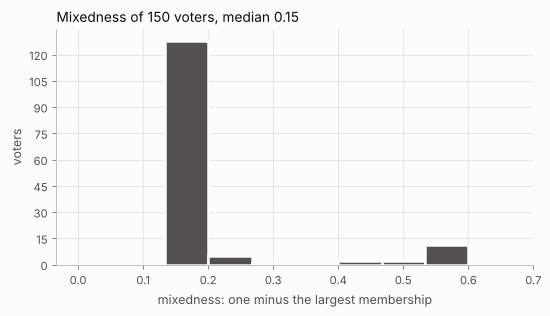

mean mixedness of the voters planted with a shared membership: 0.31
mean mixedness of the others:                                 0.17


In [7]:
viz.plot_mixedness(mixed)
plt.show()
print(
    f"mean mixedness of the voters planted with a shared membership: "
    f"{mixed.mixedness[shared].mean():.2f}"
)
print(
    f"mean mixedness of the others:                                 "
    f"{mixed.mixedness[~shared].mean():.2f}"
)

Each voter is placed between the groups by its memberships: the shared voters sit
between two vertices.

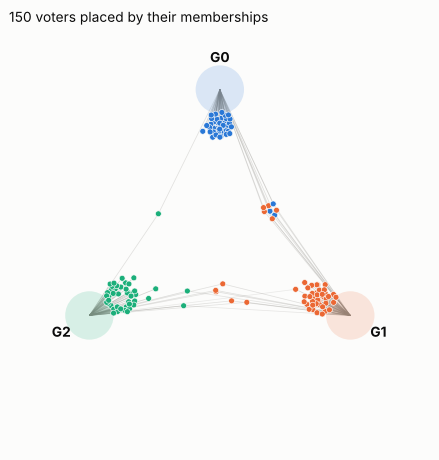

In [8]:
viz.draw_memberships(mixed)
plt.show()

**Roles from block to block.** A voter follows one group on each block; a band between
two different groups is a change of role. `role_changes(0, 1)` gives the same numbers as
a table: entry `[q, r]` counts the voters who follow `q` on block 0 and `r` on block 1.

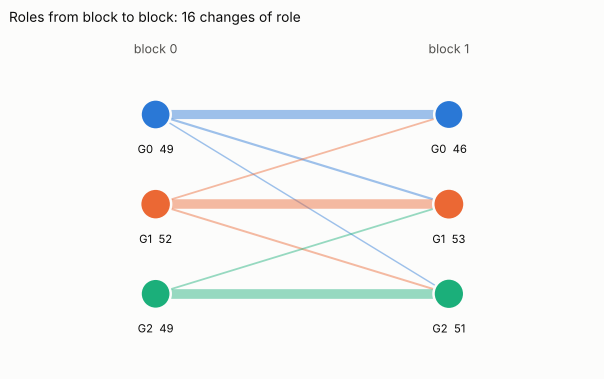

[[43  5  1]
 [ 3 45  4]
 [ 0  3 46]]


In [9]:
viz.draw_roles(mixed)
plt.show()
print(mixed.role_changes(0, 1))

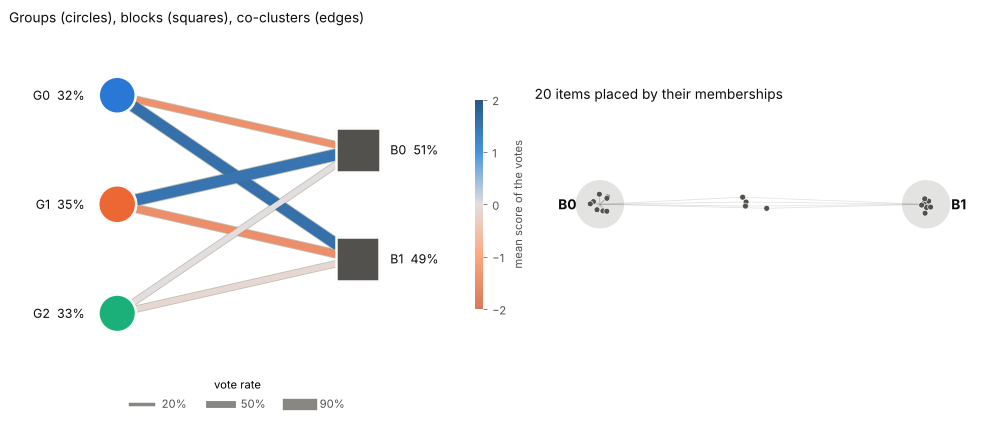

In [10]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
viz.draw_coclustering(mixed, ax=left)
viz.draw_memberships(mixed, side="items", ax=right)
plt.show()

## 5. One membership or mixed? Compare on held-out votes

The MM-OLBM has no integrated likelihood: its shape and its interest are judged on
**held-out cells**. A tenth of the shown cells is treated as never shown
(`VoteMatrix.hold_out`), both models are estimated on the rest, and each gives the
log-probability of the held-out answers (`log_probability`). Larger is better.

In [11]:
rng = np.random.default_rng(1)
held = votes.shown & (rng.random(votes.shape) < 0.1)
training = votes.hold_out(held)

for name, model in (
    (
        "one group per voter",
        LatentBlockModel(n_groups=3, n_blocks=2, initialization=SpectralStart()),
    ),
    (
        "mixed memberships",
        MixedMembershipBlockModel(
            n_groups=3, n_blocks=2, n_starts=2, max_iterations=400, initialization=SpectralStart()
        ),
    ),
):
    fitted = model.estimate(training, seed=0).value
    held_out = fitted.log_probability(votes)[held].mean()
    print(f"{name:<20} mean log-probability of {held.sum()} held-out cells: {held_out:.4f}")

one group per voter  mean log-probability of 276 held-out cells: -1.3743


mixed memberships    mean log-probability of 276 held-out cells: -1.2620


**References.** Airoldi, Blei, Fienberg and Xing (2008), *Mixed membership stochastic
blockmodels*, JMLR 9. Dempster, Laird and Rubin (1977), *Maximum likelihood from
incomplete data via the EM algorithm*, JRSS B 39(1). Corneli, Bouveyron and Latouche
(2020) for the ordinal response model.